In [ ]:
import sys

print(sys.executable)

E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe


In [2]:
import sys, torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
PyTorch: 2.11.0+cu128
PyTorch CUDA build: 12.8
CUDA available: True
GPU count: 1


In [ ]:
# %pip uninstall -y torch torchvision torchaudio

In [ ]:
# %pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

In [5]:
from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd

import torch
from torch.utils.data import Dataset, DataLoader

from PIL import Image

from sklearn.model_selection import train_test_split

from sample4geo.model import TimmModel
from sample4geo.transforms import (
    get_transforms_train,
    get_transforms_val
)

E:\python_project\Geo\Sample4Geo\Geo761\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
# ---------------------------------------------------
# Sample4Geo project
# ---------------------------------------------------

PROJECT_ROOT = Path(
    r"E:\python_project\Geo\Sample4Geo"
)

# ORIGINAL BASELINE CHECKPOINT
# NEVER SAVE TO THIS PATH
BASELINE_CHECKPOINT = (
    PROJECT_ROOT
    / "pretrained"
    / "cvusa"
    / "convnext_base.fb_in22k_ft_in1k_384"
    / "weights_e40_98.6830.pth"
)

# ---------------------------------------------------
# Fine-tuning output directory
# ---------------------------------------------------

FT_DIR = (
    PROJECT_ROOT
    / "FT"
    / "CVIAN_run01"
)

FT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Baseline checkpoint:")
print(BASELINE_CHECKPOINT)

print("\nFine-tuning output:")
print(FT_DIR)

Baseline checkpoint:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth

Fine-tuning output:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01


In [7]:
def sha256_file(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


baseline_hash = sha256_file(
    BASELINE_CHECKPOINT
)

print("Baseline SHA256:")
print(baseline_hash)

Baseline SHA256:
739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23


In [8]:
with open(
    FT_DIR / "baseline_sha256.txt",
    "w"
) as f:
    f.write(baseline_hash)

In [9]:
CVIAN_ROOT = Path(
    r"E:\python_project\Geo\CVIAN"
)

GROUND_ROOT = (
    CVIAN_ROOT
    / "panoroma_split"
    / "00_SVI"
)

SATELLITE_ROOT = (
    CVIAN_ROOT
    / "01_Satellite"
)

print("Ground:", GROUND_ROOT)
print("Satellite:", SATELLITE_ROOT)

Ground: E:\python_project\Geo\CVIAN\panoroma_split\00_SVI
Satellite: E:\python_project\Geo\CVIAN\01_Satellite


In [10]:
allowed_extensions = {
    ".png",
    ".jpg",
    ".jpeg"
}

rows = []


for left_path in GROUND_ROOT.rglob("*_left.*"):

    if left_path.suffix.lower() not in allowed_extensions:
        continue

    # Example:
    # 104078525924854_left
    #          ↓
    # 104078525924854

    pair_id = left_path.stem.removesuffix(
        "_left"
    )

    # Find corresponding right image
    right_path = None

    for ext in allowed_extensions:

        candidate = (
            left_path.parent
            / f"{pair_id}_right{ext}"
        )

        if candidate.exists():
            right_path = candidate
            break


    if right_path is None:
        print(
            "Missing right:",
            pair_id
        )
        continue


    # Damage class / relative folder
    relative_folder = (
        left_path.parent
        .relative_to(GROUND_ROOT)
    )

    # Find corresponding satellite
    satellite_path = None

    satellite_folder = (
        SATELLITE_ROOT
        / relative_folder
    )

    for ext in allowed_extensions:

        candidate = (
            satellite_folder
            / f"{pair_id}{ext}"
        )

        if candidate.exists():
            satellite_path = candidate
            break


    if satellite_path is None:
        print(
            "Missing satellite:",
            pair_id
        )
        continue


    rows.append({
        "pair_id": pair_id,

        "damage_class":
            str(relative_folder),

        "left_path":
            str(left_path),

        "right_path":
            str(right_path),

        "satellite_path":
            str(satellite_path)
    })

In [11]:
manifest = pd.DataFrame(rows)

print(
    "Valid CVIAN locations:",
    len(manifest)
)

display(
    manifest.tail()
)

Valid CVIAN locations: 4121


,pair_id,damage_class,left_path,right_path,satellite_path
4116,992918858569781,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4117,993596978488978,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4118,996333938050866,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4119,997435777936275,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4120,998859738218060,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...


In [12]:
manifest.to_csv(
    FT_DIR / "manifest.csv",
    index=False
)

### Split TRAIN / VALIDATION by location

In [13]:
train_df, val_df = train_test_split(
    manifest,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

print(
    "Training locations:",
    len(train_df)
)

print(
    "Validation locations:",
    len(val_df)
)

Training locations: 3502
Validation locations: 619


In [14]:
train_df.to_csv(
    FT_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    FT_DIR / "val.csv",
    index=False
)

### Load a NEW model from the baseline checkpoint

In [15]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model_name = (
    "convnext_base.fb_in22k_ft_in1k_384"
)

finetune_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

### Load your baseline checkpoint:

In [16]:
state_dict = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu"
)

load_result = (
    finetune_model.load_state_dict(
        state_dict,
        strict=False
    )
)

print(
    "Missing keys:",
    load_result.missing_keys
)

print(
    "Unexpected keys:",
    load_result.unexpected_keys
)

Missing keys: []
Unexpected keys: []


In [17]:
finetune_model = (
    finetune_model.to(device)
)

print(
    "Device:",
    device
)

Device: cuda


### get normalization values

In [18]:
data_config = (
    finetune_model.get_config()
)

mean = data_config["mean"]
std = data_config["std"]

print("Mean:", mean)
print("Std:", std)

Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


### define fine-tuning image size

In [19]:
image_size_ground = (
    384,
    384
)

image_size_satellite = (
    384,
    384
)

### create training and validation transforms

In [20]:
sat_transform_train, ground_transform_train = (
    get_transforms_train(
        image_size_satellite,
        image_size_ground,
        mean=mean,
        std=std
    )
)

E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:39: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=90, quality_upper=100, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:41: UserWarning: Argument(s) 'always_apply' are not valid for transform ColorJitter
  A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.15, always_apply=False, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:48: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=25,
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:63: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=90, quality_upper=100, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:65: UserW

In [21]:
sat_transform_val, ground_transform_val = (
    get_transforms_val(
        image_size_satellite,
        image_size_ground,
        mean=mean,
        std=std
    )
)

### custom CVIAN Dataset
During traning randomly choose left or right database

In [22]:
class CVIANPairDataset(Dataset):

    def __init__(
        self,
        dataframe,
        ground_transform,
        satellite_transform,
        training=True
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.ground_transform = (
            ground_transform
        )

        self.satellite_transform = (
            satellite_transform
        )

        self.training = training


    def __len__(self):

        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # -------------------------------------------
        # Choose ground view
        # -------------------------------------------

        if self.training:

            # Random left/right each time
            if random.random() < 0.5:

                ground_path = (
                    row["left_path"]
                )

                view = "left"

            else:

                ground_path = (
                    row["right_path"]
                )

                view = "right"


        else:

            # Deterministic validation:
            # alternate left/right by sample
            if idx % 2 == 0:

                ground_path = (
                    row["left_path"]
                )

                view = "left"

            else:

                ground_path = (
                    row["right_path"]
                )

                view = "right"


        satellite_path = (
            row["satellite_path"]
        )


        # -------------------------------------------
        # Load images
        # -------------------------------------------

        ground_img = np.array(
            Image.open(
                ground_path
            ).convert("RGB")
        )

        satellite_img = np.array(
            Image.open(
                satellite_path
            ).convert("RGB")
        )


        # -------------------------------------------
        # Transform
        # -------------------------------------------

        ground_tensor = (
            self.ground_transform(
                image=ground_img
            )["image"]
        )

        satellite_tensor = (
            self.satellite_transform(
                image=satellite_img
            )["image"]
        )


        return {

            "ground":
                ground_tensor,

            "satellite":
                satellite_tensor,

            "pair_id":
                row["pair_id"],

            "view":
                view
        }

### Instantiate datasets

In [25]:
train_dataset = CVIANPairDataset(
    dataframe=train_df,
    ground_transform=
        ground_transform_train,
    satellite_transform=
        sat_transform_train,
    training=True
)

val_dataset = CVIANPairDataset(
    dataframe=val_df,
    ground_transform=
        ground_transform_val,
    satellite_transform=
        sat_transform_val,
    training=False
)

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

Train: 3502
Validation: 619


### DataLoaders

In [26]:
batch_size = 16

In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

### inspect ONE batch before training

In [28]:
batch = next(
    iter(train_loader)
)

print(
    "Ground:",
    batch["ground"].shape
)

print(
    "Satellite:",
    batch["satellite"].shape
)

print(
    "Pair IDs:",
    batch["pair_id"][:3]
)

print(
    "Views:",
    batch["view"][:3]
)

Ground: torch.Size([16, 3, 384, 384])
Satellite: torch.Size([16, 3, 384, 384])
Pair IDs: ['568736915338831', '2462266427273846', '925113528556762']
Views: ['right', 'right', 'left']


### test one forward pass

In [30]:
ground_batch = (
    batch["ground"]
    .to(device)
)

satellite_batch = (
    batch["satellite"]
    .to(device)
)

In [31]:
finetune_model.eval()

with torch.inference_mode():

    ground_features = (
        finetune_model(
            ground_batch
        )
    )

    satellite_features = (
        finetune_model(
            satellite_batch
        )
    )


print(
    "Ground embedding:",
    ground_features.shape
)

print(
    "Satellite embedding:",
    satellite_features.shape
)

Ground embedding: torch.Size([16, 1024])
Satellite embedding: torch.Size([16, 1024])


### training configuration and checkpoint safety

In [33]:
from pathlib import Path
import math
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F


# ---------------------------------------------------
# Fine-tuning output paths
# ---------------------------------------------------

BEST_MODEL_PATH = FT_DIR / "best_model.pth"
LAST_MODEL_PATH = FT_DIR / "last_model.pth"
HISTORY_PATH = FT_DIR / "training_history.csv"


# ---------------------------------------------------
# Safety: baseline must NEVER equal FT output
# ---------------------------------------------------

assert str(BASELINE_CHECKPOINT).lower() != str(BEST_MODEL_PATH).lower()
assert str(BASELINE_CHECKPOINT).lower() != str(LAST_MODEL_PATH).lower()


# ---------------------------------------------------
# Reproducibility
# ---------------------------------------------------

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------
# Training configuration
# ---------------------------------------------------

epochs = 10

learning_rate = 1e-5

weight_decay = 0.01

label_smoothing = 0.1

initial_temperature = 0.07

warmup_epochs = 1


print("Fine-tuned models will be saved to:")
print(FT_DIR)

print("\nOriginal baseline remains at:")
print(BASELINE_CHECKPOINT)

Fine-tuned models will be saved to:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01

Original baseline remains at:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth


### symmetric InfoNCE loss

In [34]:
criterion = torch.nn.CrossEntropyLoss(
    label_smoothing=label_smoothing
)


# Learnable temperature
logit_scale = torch.nn.Parameter(
    torch.tensor(
        np.log(1.0 / initial_temperature),
        dtype=torch.float32,
        device=device
    )
)


def symmetric_info_nce(
    ground_features,
    satellite_features,
    logit_scale
):

    # L2 normalization
    ground_features = F.normalize(
        ground_features,
        p=2,
        dim=1
    )

    satellite_features = F.normalize(
        satellite_features,
        p=2,
        dim=1
    )

    # Learnable 1 / temperature
    scale = logit_scale.exp().clamp(
        max=100
    )

    # B x B similarity matrix
    logits = (
        scale
        * ground_features
        @ satellite_features.T
    )

    # Correct matches are on diagonal
    labels = torch.arange(
        logits.shape[0],
        device=logits.device
    )

    # Ground -> Satellite
    loss_g2s = criterion(
        logits,
        labels
    )

    # Satellite -> Ground
    loss_s2g = criterion(
        logits.T,
        labels
    )

    # Symmetric loss
    loss = (
        loss_g2s + loss_s2g
    ) / 2

    return loss

### optimizer

In [35]:
optimizer = torch.optim.AdamW(
    [
        {
            "params":
                finetune_model.parameters()
        },

        {
            "params":
                [logit_scale],

            "weight_decay":
                0.0
        }
    ],
    lr=learning_rate,
    weight_decay=weight_decay
)


print(
    "Learning rate:",
    learning_rate
)

print(
    "Initial temperature:",
    1 / logit_scale.exp().item()
)

Learning rate: 1e-05
Initial temperature: 0.0699999959945681


### cosine scheduler with warm-up

In [36]:
total_steps = (
    len(train_loader)
    * epochs
)

warmup_steps = (
    len(train_loader)
    * warmup_epochs
)


def lr_lambda(current_step):

    # Warm-up
    if current_step < warmup_steps:

        return float(
            current_step + 1
        ) / float(
            max(1, warmup_steps)
        )

    # Cosine decay
    progress = (
        current_step - warmup_steps
    ) / (
        total_steps - warmup_steps
    )

    return 0.5 * (
        1.0
        + math.cos(
            math.pi * progress
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)


print("Training steps:", total_steps)
print("Warm-up steps:", warmup_steps)

Training steps: 2180
Warm-up steps: 218


mixed precision - saves a lot of VRAM and should speed things up on GPU

In [37]:
use_amp = (
    torch.cuda.is_available()
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print(
    "Mixed precision:",
    use_amp
)

Mixed precision: True


### validation retrieval function

In [38]:
def evaluate_retrieval(
    model,
    dataloader,
    device
):

    model.eval()

    all_ground = []
    all_satellite = []

    with torch.inference_mode():

        for batch in dataloader:

            ground = batch[
                "ground"
            ].to(
                device,
                non_blocking=True
            )

            satellite = batch[
                "satellite"
            ].to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                "cuda",
                enabled=use_amp
            ):

                ground_features = model(
                    ground
                )

                satellite_features = model(
                    satellite
                )


            ground_features = F.normalize(
                ground_features,
                p=2,
                dim=1
            )

            satellite_features = F.normalize(
                satellite_features,
                p=2,
                dim=1
            )


            all_ground.append(
                ground_features.cpu()
            )

            all_satellite.append(
                satellite_features.cpu()
            )


    # -----------------------------------------------
    # Combine all validation batches
    # -----------------------------------------------

    all_ground = torch.cat(
        all_ground,
        dim=0
    )

    all_satellite = torch.cat(
        all_satellite,
        dim=0
    )


    # -----------------------------------------------
    # Full query × reference similarity matrix
    # -----------------------------------------------

    similarity_matrix = (
        all_ground
        @ all_satellite.T
    )


    n = similarity_matrix.shape[0]

    correct_indices = torch.arange(n)


    recalls = {}

    for k in [1, 5, 10]:

        actual_k = min(
            k,
            n
        )

        top_k = (
            similarity_matrix
            .topk(
                actual_k,
                dim=1
            )
            .indices
        )

        correct = (
            top_k
            == correct_indices[:, None]
        ).any(dim=1)

        recalls[k] = (
            correct.float()
            .mean()
            .item()
        )


    # Mean similarity of actual positive pairs
    positive_similarity = (
        similarity_matrix
        .diagonal()
        .mean()
        .item()
    )


    return (
        recalls,
        positive_similarity
    )

### measure CVUSA baseline on CVIAN BEFORE training

In [39]:
baseline_recalls, baseline_positive_sim = (
    evaluate_retrieval(
        finetune_model,
        val_loader,
        device
    )
)


print("Before fine-tuning")
print("------------------")

print(
    f"Recall@1:  "
    f"{baseline_recalls[1]:.4f}"
)

print(
    f"Recall@5:  "
    f"{baseline_recalls[5]:.4f}"
)

print(
    f"Recall@10: "
    f"{baseline_recalls[10]:.4f}"
)

print(
    f"Mean positive similarity: "
    f"{baseline_positive_sim:.4f}"
)

Before fine-tuning
------------------
Recall@1:  0.0145
Recall@5:  0.0501
Recall@10: 0.1018
Mean positive similarity: 0.1976


### actual training loop

In [40]:
history = []

best_recall1 = -1.0


for epoch in range(
    1,
    epochs + 1
):

    # ===============================================
    # TRAIN
    # ===============================================

    finetune_model.train()

    running_loss = 0.0


    for step, batch in enumerate(
        train_loader,
        start=1
    ):

        ground = batch[
            "ground"
        ].to(
            device,
            non_blocking=True
        )

        satellite = batch[
            "satellite"
        ].to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        # -------------------------------------------
        # Forward pass
        # -------------------------------------------

        with torch.amp.autocast(
            "cuda",
            enabled=use_amp
        ):

            ground_features = (
                finetune_model(
                    ground
                )
            )

            satellite_features = (
                finetune_model(
                    satellite
                )
            )


            loss = symmetric_info_nce(
                ground_features,
                satellite_features,
                logit_scale
            )


        # -------------------------------------------
        # Backpropagation
        # -------------------------------------------

        scaler.scale(
            loss
        ).backward()


        scaler.step(
            optimizer
        )

        scaler.update()

        scheduler.step()


        running_loss += (
            loss.item()
        )


        # Print progress occasionally
        if (
            step % 50 == 0
            or step == len(train_loader)
        ):

            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"Step {step:04d}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )


    average_train_loss = (
        running_loss
        / len(train_loader)
    )


    # ===============================================
    # VALIDATE
    # ===============================================

    recalls, positive_sim = (
        evaluate_retrieval(
            finetune_model,
            val_loader,
            device
        )
    )


    recall1 = recalls[1]
    recall5 = recalls[5]
    recall10 = recalls[10]


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    temperature = (
        1 /
        logit_scale.exp().item()
    )


    # ===============================================
    # HISTORY
    # ===============================================

    history.append({

        "epoch":
            epoch,

        "train_loss":
            average_train_loss,

        "recall@1":
            recall1,

        "recall@5":
            recall5,

        "recall@10":
            recall10,

        "positive_similarity":
            positive_sim,

        "learning_rate":
            current_lr,

        "temperature":
            temperature
    })


    print(
        "\n"
        f"Epoch {epoch:02d} complete\n"
        f"Train loss: {average_train_loss:.4f}\n"
        f"Recall@1:   {recall1:.4f}\n"
        f"Recall@5:   {recall5:.4f}\n"
        f"Recall@10:  {recall10:.4f}\n"
        f"Positive similarity: {positive_sim:.4f}\n"
        f"Temperature: {temperature:.4f}\n"
    )


    # ===============================================
    # SAVE BEST MODEL
    # ===============================================

    if recall1 > best_recall1:

        best_recall1 = recall1

        torch.save(
            finetune_model.state_dict(),
            BEST_MODEL_PATH
        )

        print(
            "✓ New best model saved:"
        )

        print(
            BEST_MODEL_PATH
        )


    # Save history after every epoch
    pd.DataFrame(
        history
    ).to_csv(
        HISTORY_PATH,
        index=False
    )


# ===================================================
# SAVE LAST MODEL
# ===================================================

torch.save(
    finetune_model.state_dict(),
    LAST_MODEL_PATH
)

print("\nTraining finished.")

print(
    "Best Recall@1:",
    best_recall1
)

print(
    "Best model:",
    BEST_MODEL_PATH
)

print(
    "Last model:",
    LAST_MODEL_PATH
)

Epoch 01/10 | Step 0050/218 | Loss 2.5489
Epoch 01/10 | Step 0100/218 | Loss 2.3756
Epoch 01/10 | Step 0150/218 | Loss 2.1756
Epoch 01/10 | Step 0200/218 | Loss 1.6716
Epoch 01/10 | Step 0218/218 | Loss 2.0015

Epoch 01 complete
Train loss: 2.3548
Recall@1:   0.0759
Recall@5:   0.1987
Recall@10:  0.2989
Positive similarity: 0.3030
Temperature: 0.0700

✓ New best model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth
Epoch 02/10 | Step 0050/218 | Loss 1.4318
Epoch 02/10 | Step 0100/218 | Loss 1.2807
Epoch 02/10 | Step 0150/218 | Loss 1.6701
Epoch 02/10 | Step 0200/218 | Loss 1.2362
Epoch 02/10 | Step 0218/218 | Loss 1.3187

Epoch 02 complete
Train loss: 1.5992
Recall@1:   0.1696
Recall@5:   0.4055
Recall@10:  0.5331
Positive similarity: 0.3988
Temperature: 0.0698

✓ New best model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth
Epoch 03/10 | Step 0050/218 | Loss 1.4387
Epoch 03/10 | Step 0100/218 | Loss 1.3355
Epoch 03/10 | Step 0150/218 | Loss

### plot training results

In [41]:
history_df = pd.DataFrame(
    history
)

display(history_df)

,epoch,train_loss,recall@1,recall@5,recall@10,positive_similarity,learning_rate,temperature
0,1,2.354815,0.075929,0.198708,0.298869,0.303012,1.000000e-05,0.069959
1,2,1.599180,0.169628,0.405493,0.533118,0.398846,9.698463e-06,0.069815
2,3,1.237029,0.224556,0.513732,0.646204,0.422791,8.830222e-06,0.069713
3,4,1.100031,0.268174,0.579968,0.715670,0.432362,7.500000e-06,0.069636
4,5,1.010709,0.303716,0.617124,0.743134,0.433036,5.868241e-06,0.069577
5,6,0.962431,0.319871,0.633280,0.768982,0.430627,4.131759e-06,0.069534
6,7,0.934554,0.326333,0.647819,0.780291,0.430703,2.500000e-06,0.069505
7,8,0.914336,0.339257,0.655897,0.798061,0.428315,1.169778e-06,0.069488
8,9,0.900496,0.340872,0.654281,0.799677,0.427720,3.015369e-07,0.069482
9,10,0.906202,0.340872,0.654281,0.801292,0.427701,0.000000e+00,0.069481


### Training loss:

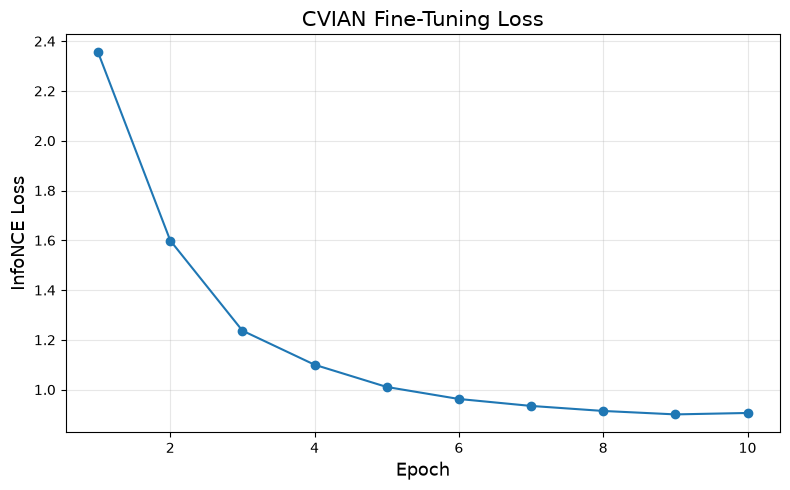

In [42]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o"
)

plt.xlabel(
    "Epoch",
    fontsize=13
)

plt.ylabel(
    "InfoNCE Loss",
    fontsize=13
)

plt.title(
    "CVIAN Fine-Tuning Loss",
    fontsize=15
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Retrieval performance:

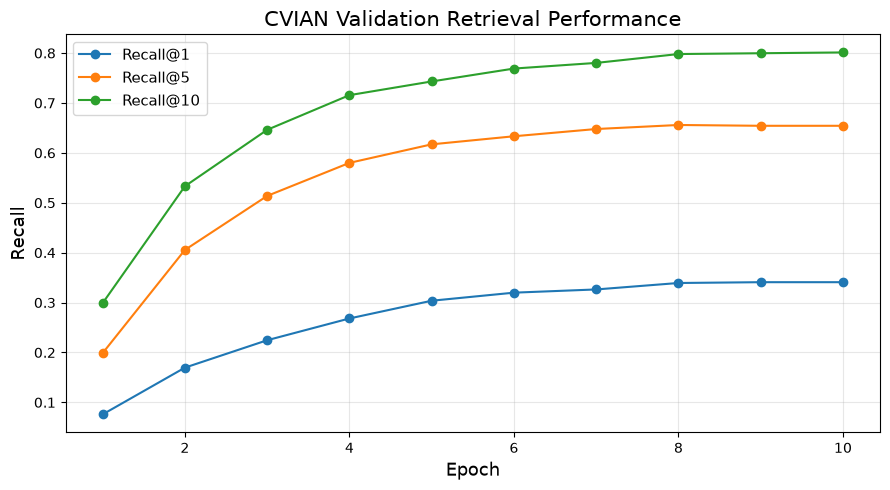

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["recall@1"],
    marker="o",
    label="Recall@1"
)

plt.plot(
    history_df["epoch"],
    history_df["recall@5"],
    marker="o",
    label="Recall@5"
)

plt.plot(
    history_df["epoch"],
    history_df["recall@10"],
    marker="o",
    label="Recall@10"
)

plt.xlabel(
    "Epoch",
    fontsize=13
)

plt.ylabel(
    "Recall",
    fontsize=13
)

plt.title(
    "CVIAN Validation Retrieval Performance",
    fontsize=15
)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### verify baseline checkpoint was untouched

In [44]:
baseline_hash_after = sha256_file(
    BASELINE_CHECKPOINT
)

print(
    "Before:",
    baseline_hash
)

print(
    "After: ",
    baseline_hash_after
)

print(
    "\nBaseline unchanged:",
    baseline_hash == baseline_hash_after
)

Before: 739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23
After:  739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23

Baseline unchanged: True


### load the best fine-tuned checkpoint

In [51]:
BEST_MODEL_PATH = (
    Path(r"E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01")
    / "best_model.pth"
)

state_dict = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu"
)

finetune_model.load_state_dict(
    state_dict,
    strict=True
)

finetune_model = finetune_model.to(device)
finetune_model.eval()

print("Loaded:", BEST_MODEL_PATH)

Loaded: E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth


In [52]:
from sample4geo.transforms import get_transforms_val

data_config = finetune_model.get_config()

mean = data_config["mean"]
std = data_config["std"]

image_size_ground = (384, 384)
image_size_satellite = (384, 384)

sat_transform_val, ground_transform_val = get_transforms_val(
    image_size_satellite,
    image_size_ground,
    mean=mean,
    std=std
)

In [53]:
def get_embedding(image_path, transform):

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    tensor = transform(
        image=img
    )["image"]

    tensor = tensor.unsqueeze(0).to(device)

    with torch.inference_mode():

        embedding = finetune_model(
            tensor
        )

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding

### calculate satellite embeddings

In [54]:
satellite_embeddings = {}

for sat_path in satellite_files:

    satellite_embedding = get_embedding(
        sat_path,
        sat_transform_val
    )

    satellite_embeddings[
        sat_path.name
    ] = satellite_embedding

print(
    "Satellite embeddings completed:",
    len(satellite_embeddings)
)

Satellite embeddings completed: 8


### compare all four ground-query types

In [55]:
satellite_files = []

for extension in ["*.png", "*.jpg", "*.jpeg"]:

    satellite_files.extend(
        satellite_folder.glob(extension)
    )

satellite_files = sorted(satellite_files)

print(
    "Number of satellite images:",
    len(satellite_files)
)

for path in satellite_files:
    print(path.name)

Number of satellite images: 8
104078525924854.png
GABRIELLE_HAWKESBAY_SATELLITEV.png
GABRIELLE_HAWKESBAY_SATELLITEV2.png
GABRIELLE_HAWKESBAY_SATELLITEV3.png
GABRIELLE_HAWKESBAY_SATELLITEV4.png
LongBay_SATELLITE.jpg
Okura_SATELLITE.jpg
RodneyWard_SATELLITE.jpg


In [56]:
results_ft = []

for query_type, ground_path in query_groups.items():

    print(f"\nProcessing: {query_type}")

    ground_embedding = get_embedding(
        ground_path,
        ground_transform_val
    )

    for sat_name, sat_embedding in satellite_embeddings.items():

        similarity = (
            ground_embedding
            @ sat_embedding.T
        ).item()

        results_ft.append({
            "query_type": query_type,
            "ground_image": ground_path.name,
            "satellite_image": sat_name,
            "cosine_similarity": similarity
        })

        print(
            f"{sat_name:45s} "
            f"{similarity:.4f}"
        )


Processing: Positive
104078525924854.png                           0.0986
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4330
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2266
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.3826
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.4629
LongBay_SATELLITE.jpg                         0.1819
Okura_SATELLITE.jpg                           0.2024
RodneyWard_SATELLITE.jpg                      0.2626

Processing: Easy Negative
104078525924854.png                           0.0201
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4271
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2828
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.3865
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.4098
LongBay_SATELLITE.jpg                         0.2515
Okura_SATELLITE.jpg                           0.1042
RodneyWard_SATELLITE.jpg                      0.1423

Processing: Random Negative
104078525924854.png                           0.2166
GABRIELLE_HAWKESBAY_S

### create the DataFrame

In [57]:
df_ft = pd.DataFrame(
    results_ft
)

display(df_ft)

,query_type,ground_image,satellite_image,cosine_similarity
0,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,104078525924854.png,0.098614
1,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.432983
2,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.226586
3,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.382639
4,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.462861
5,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,LongBay_SATELLITE.jpg,0.181894
6,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,Okura_SATELLITE.jpg,0.202387
7,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,RodneyWard_SATELLITE.jpg,0.262567
8,Easy Negative,Easy_negative.png,104078525924854.png,0.020149
9,Easy Negative,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.427092


### convert to the similarity matrix

In [58]:
heatmap_ft = df_ft.pivot(
    index="query_type",
    columns="satellite_image",
    values="cosine_similarity"
)

row_order = [
    "Positive",
    "Easy Negative",
    "Random Negative",
    "Hard Negative"
]

heatmap_ft = heatmap_ft.reindex(
    row_order
)

display(heatmap_ft)

satellite_image,104078525924854.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,LongBay_SATELLITE.jpg,Okura_SATELLITE.jpg,RodneyWard_SATELLITE.jpg
query_type,,,,,,,,
Positive,0.098614,0.432983,0.226586,0.382639,0.462861,0.181894,0.202387,0.262567
Easy Negative,0.020149,0.427092,0.282807,0.386468,0.409809,0.251473,0.104207,0.142296
Random Negative,0.216643,0.389921,0.345769,0.419058,0.325716,0.202915,0.139357,0.156744
Hard Negative,0.013775,0.299641,0.224837,0.174957,0.209307,0.114865,0.204884,0.130881


### draw the same green/yellow heatmap

In [59]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    "yellow_green",
    [
        "#FFFF33",   # bright yellow - lower similarity
        "#ADFF2F",   # yellow-green
        "#66FF66",   # light green
        "#00FF00"    # bright green - higher similarity
    ]
)

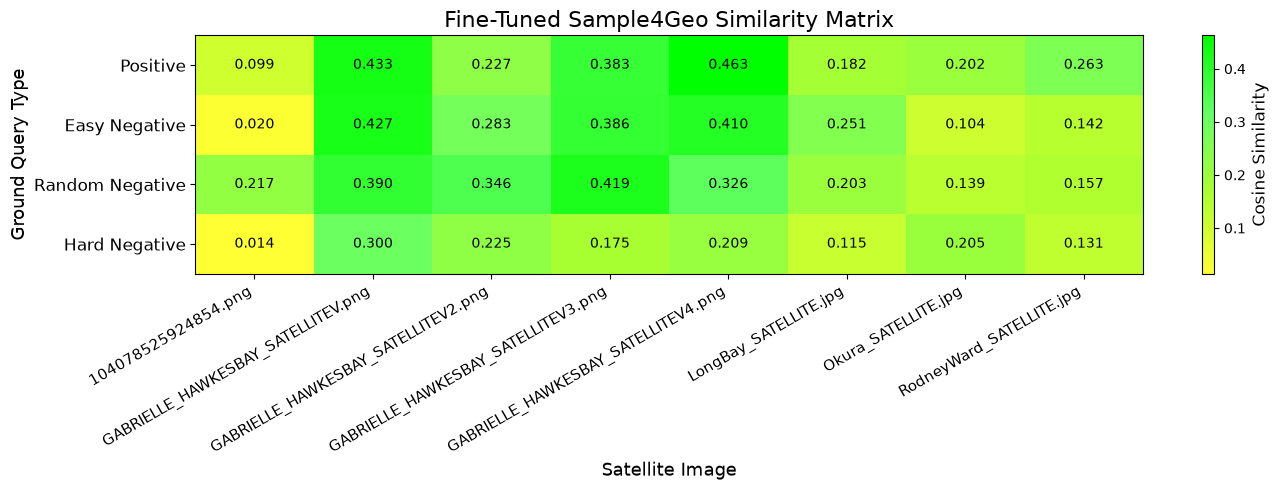

In [60]:
plt.figure(
    figsize=(14, 5)
)

im = plt.imshow(
    heatmap_ft.values,
    aspect="auto",
    cmap=custom_cmap
)

plt.xticks(
    ticks=range(
        len(heatmap_ft.columns)
    ),
    labels=heatmap_ft.columns,
    rotation=30,
    ha="right",
    fontsize=11
)

plt.yticks(
    ticks=range(
        len(heatmap_ft.index)
    ),
    labels=heatmap_ft.index,
    fontsize=12
)

plt.title(
    "Fine-Tuned Sample4Geo Similarity Matrix",
    fontsize=16
)

plt.xlabel(
    "Satellite Image",
    fontsize=13
)

plt.ylabel(
    "Ground Query Type",
    fontsize=13
)

cbar = plt.colorbar(im)

cbar.set_label(
    "Cosine Similarity",
    fontsize=12
)

# Numeric values
for i in range(
    heatmap_ft.shape[0]
):

    for j in range(
        heatmap_ft.shape[1]
    ):

        value = heatmap_ft.values[
            i,
            j
        ]

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )

plt.tight_layout()

plt.show()

### load baseline and fine-tuned models separately

In [61]:
from sample4geo.model import TimmModel
import torch

model_name = "convnext_base.fb_in22k_ft_in1k_384"

# ---------------------------------------------------
# Baseline model
# ---------------------------------------------------

baseline_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

baseline_state = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu"
)

baseline_model.load_state_dict(
    baseline_state,
    strict=True
)

baseline_model = baseline_model.to(device)
baseline_model.eval()


# ---------------------------------------------------
# Fine-tuned model
# ---------------------------------------------------

finetuned_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

finetuned_state = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu"
)

finetuned_model.load_state_dict(
    finetuned_state,
    strict=True
)

finetuned_model = finetuned_model.to(device)
finetuned_model.eval()


print("Baseline and fine-tuned models loaded.")

Baseline and fine-tuned models loaded.


### retrieval evaluation function

In [62]:
import torch.nn.functional as F


def evaluate_retrieval(
    model,
    dataloader,
    device
):

    model.eval()

    all_ground = []
    all_satellite = []

    with torch.inference_mode():

        for batch in dataloader:

            ground = batch["ground"].to(
                device,
                non_blocking=True
            )

            satellite = batch["satellite"].to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):

                ground_features = model(
                    ground
                )

                satellite_features = model(
                    satellite
                )

            ground_features = F.normalize(
                ground_features,
                p=2,
                dim=1
            )

            satellite_features = F.normalize(
                satellite_features,
                p=2,
                dim=1
            )

            all_ground.append(
                ground_features.cpu()
            )

            all_satellite.append(
                satellite_features.cpu()
            )


    # Combine all validation batches
    all_ground = torch.cat(
        all_ground,
        dim=0
    )

    all_satellite = torch.cat(
        all_satellite,
        dim=0
    )


    # Query × satellite similarity matrix
    similarity_matrix = (
        all_ground
        @ all_satellite.T
    )


    n = similarity_matrix.shape[0]

    correct_indices = torch.arange(n)

    recalls = {}

    for k in [1, 5, 10]:

        actual_k = min(k, n)

        top_k = similarity_matrix.topk(
            actual_k,
            dim=1
        ).indices

        correct = (
            top_k
            == correct_indices[:, None]
        ).any(dim=1)

        recalls[k] = (
            correct.float()
            .mean()
            .item()
        )


    positive_similarity = (
        similarity_matrix
        .diagonal()
        .mean()
        .item()
    )


    return recalls, positive_similarity

### evaluate the baseline model

In [63]:
baseline_recalls, baseline_positive_sim = evaluate_retrieval(
    baseline_model,
    val_loader,
    device
)

print("BASELINE")
print("------------------")

print(
    f"Recall@1:  {baseline_recalls[1]:.4f}"
)

print(
    f"Recall@5:  {baseline_recalls[5]:.4f}"
)

print(
    f"Recall@10: {baseline_recalls[10]:.4f}"
)

print(
    f"Mean positive similarity: "
    f"{baseline_positive_sim:.4f}"
)

BASELINE
------------------
Recall@1:  0.0145
Recall@5:  0.0501
Recall@10: 0.1018
Mean positive similarity: 0.1976


### evaluate the fine-tuned model

In [64]:
ft_recalls, ft_positive_sim = evaluate_retrieval(
    finetuned_model,
    val_loader,
    device
)

print("FINE-TUNED")
print("------------------")

print(
    f"Recall@1:  {ft_recalls[1]:.4f}"
)

print(
    f"Recall@5:  {ft_recalls[5]:.4f}"
)

print(
    f"Recall@10: {ft_recalls[10]:.4f}"
)

print(
    f"Mean positive similarity: "
    f"{ft_positive_sim:.4f}"
)

FINE-TUNED
------------------
Recall@1:  0.3409
Recall@5:  0.6543
Recall@10: 0.7997
Mean positive similarity: 0.4277


### create before/after comparison table

In [65]:
import pandas as pd

comparison_df = pd.DataFrame({

    "Metric": [
        "Recall@1",
        "Recall@5",
        "Recall@10",
        "Mean Positive Similarity"
    ],

    "Before Fine-Tuning": [
        baseline_recalls[1],
        baseline_recalls[5],
        baseline_recalls[10],
        baseline_positive_sim
    ],

    "After Fine-Tuning": [
        ft_recalls[1],
        ft_recalls[5],
        ft_recalls[10],
        ft_positive_sim
    ]
})


comparison_df["Absolute Improvement"] = (
    comparison_df["After Fine-Tuning"]
    - comparison_df["Before Fine-Tuning"]
)


display(
    comparison_df.round(4)
)

,Metric,Before Fine-Tuning,After Fine-Tuning,Absolute Improvement
0,Recall@1,0.0145,0.3409,0.3263
1,Recall@5,0.0501,0.6543,0.6042
2,Recall@10,0.1018,0.7997,0.6979
3,Mean Positive Similarity,0.1976,0.4277,0.2301


### percentage-point Recall improvement

In [66]:
for k in [1, 5, 10]:

    before = baseline_recalls[k]
    after = ft_recalls[k]

    improvement_pp = (
        after - before
    ) * 100

    print(
        f"Recall@{k}: "
        f"{before * 100:.2f}% "
        f"→ {after * 100:.2f}% "
        f"(+{improvement_pp:.2f} percentage points)"
    )

Recall@1: 1.45% → 34.09% (+32.63 percentage points)
Recall@5: 5.01% → 65.43% (+60.42 percentage points)
Recall@10: 10.18% → 79.97% (+69.79 percentage points)


### publication-style before/after bar chart

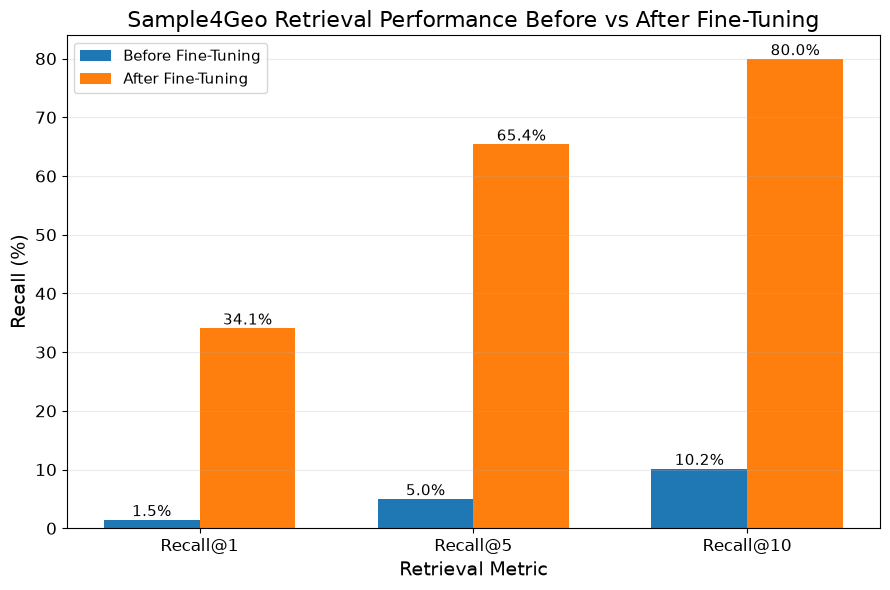

In [67]:
import numpy as np
import matplotlib.pyplot as plt


metrics = [
    "Recall@1",
    "Recall@5",
    "Recall@10"
]

before = np.array([
    baseline_recalls[1],
    baseline_recalls[5],
    baseline_recalls[10]
]) * 100

after = np.array([
    ft_recalls[1],
    ft_recalls[5],
    ft_recalls[10]
]) * 100


x = np.arange(
    len(metrics)
)

width = 0.35


plt.figure(
    figsize=(9, 6)
)

bars_before = plt.bar(
    x - width / 2,
    before,
    width,
    label="Before Fine-Tuning"
)

bars_after = plt.bar(
    x + width / 2,
    after,
    width,
    label="After Fine-Tuning"
)


plt.ylabel(
    "Recall (%)",
    fontsize=14
)

plt.xlabel(
    "Retrieval Metric",
    fontsize=14
)

plt.title(
    "Sample4Geo Retrieval Performance Before vs After Fine-Tuning",
    fontsize=16
)

plt.xticks(
    x,
    metrics,
    fontsize=12
)

plt.yticks(
    fontsize=12
)

plt.legend(
    fontsize=11
)

plt.grid(
    axis="y",
    alpha=0.25
)


# Add values above bars
for bars in [
    bars_before,
    bars_after
]:

    for bar in bars:

        value = bar.get_height()

        plt.text(
            bar.get_x()
            + bar.get_width() / 2,
            value,
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=11
        )


plt.tight_layout()

plt.show()

## Best view fine tunning

### CVian best view directory

In [68]:
BESTVIEW_FT_DIR = Path(
    r"E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01"
)

BESTVIEW_FT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BESTVIEW_MODEL_PATH = (
    BESTVIEW_FT_DIR /
    "best_model.pth"
)

BESTVIEW_LAST_PATH = (
    BESTVIEW_FT_DIR /
    "last_model.pth"
)

BESTVIEW_HISTORY_PATH = (
    BESTVIEW_FT_DIR /
    "training_history.csv"
)

print(BESTVIEW_FT_DIR)

E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01


### load the ORIGINAL baseline model for view selection

In [69]:
baseline_selector = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

baseline_selector.load_state_dict(
    torch.load(
        BASELINE_CHECKPOINT,
        map_location="cpu"
    ),
    strict=True
)

baseline_selector = baseline_selector.to(device)
baseline_selector.eval()

print("Baseline selector loaded.")

Baseline selector loaded.


### helper function

In [70]:
def get_embedding_for_model(
    image_path,
    transform,
    model
):

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    tensor = transform(
        image=img
    )["image"]

    tensor = (
        tensor
        .unsqueeze(0)
        .to(device)
    )

    with torch.inference_mode():

        embedding = model(
            tensor
        )

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding

### determine best LEFT/RIGHT for every TRAINING pair

In [72]:
sat_transform_selector = sat_transform_val
ground_transform_selector = ground_transform_val

In [73]:
bestview_rows = []

for i, row in train_df.iterrows():

    left_path = Path(
        row["left_path"]
    )

    right_path = Path(
        row["right_path"]
    )

    sat_path = Path(
        row["satellite_path"]
    )


    # Satellite embedding
    sat_embedding = get_embedding_for_model(
        sat_path,
        sat_transform_selector,
        baseline_selector
    )


    # Left embedding
    left_embedding = get_embedding_for_model(
        left_path,
        ground_transform_selector,
        baseline_selector
    )


    # Right embedding
    right_embedding = get_embedding_for_model(
        right_path,
        ground_transform_selector,
        baseline_selector
    )


    # Similarities
    left_similarity = (
        left_embedding
        @ sat_embedding.T
    ).item()

    right_similarity = (
        right_embedding
        @ sat_embedding.T
    ).item()


    # Select best
    if left_similarity >= right_similarity:

        best_view = "left"
        best_ground_path = left_path
        best_similarity = left_similarity

    else:

        best_view = "right"
        best_ground_path = right_path
        best_similarity = right_similarity


    bestview_rows.append({

        "pair_id":
            row["pair_id"],

        "damage_class":
            row["damage_class"],

        "left_path":
            str(left_path),

        "right_path":
            str(right_path),

        "satellite_path":
            str(sat_path),

        "left_similarity":
            left_similarity,

        "right_similarity":
            right_similarity,

        "best_view":
            best_view,

        "best_ground_path":
            str(best_ground_path),

        "best_similarity":
            best_similarity
    })


    if (i + 1) % 100 == 0:

        print(
            f"Processed {i + 1} training pairs"
        )

Processed 100 training pairs
Processed 200 training pairs
Processed 300 training pairs
Processed 400 training pairs
Processed 500 training pairs
Processed 600 training pairs
Processed 700 training pairs
Processed 800 training pairs
Processed 900 training pairs
Processed 1000 training pairs
Processed 1100 training pairs
Processed 1200 training pairs
Processed 1300 training pairs
Processed 1400 training pairs
Processed 1500 training pairs
Processed 1600 training pairs
Processed 1700 training pairs
Processed 1800 training pairs
Processed 1900 training pairs
Processed 2000 training pairs
Processed 2100 training pairs
Processed 2200 training pairs
Processed 2300 training pairs
Processed 2400 training pairs
Processed 2500 training pairs
Processed 2600 training pairs
Processed 2700 training pairs
Processed 2800 training pairs
Processed 2900 training pairs
Processed 3000 training pairs
Processed 3100 training pairs
Processed 3200 training pairs
Processed 3300 training pairs
Processed 3400 trai

### inspect and save best-view manifest

In [74]:
train_bestview_df = pd.DataFrame(
    bestview_rows
)

display(
    train_bestview_df.head()
)

,pair_id,damage_class,left_path,right_path,satellite_path,left_similarity,right_similarity,best_view,best_ground_path,best_similarity
0,1314979726096443,0_MinorDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\0_Min...,0.091917,0.089892,left,E:\python_project\Geo\CVIAN\panoroma_split\00_...,0.091917
1,234813832691019,0_MinorDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\0_Min...,0.324771,0.239997,left,E:\python_project\Geo\CVIAN\panoroma_split\00_...,0.324771
2,847731372971163,1_ModerateDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\1_Mod...,0.244193,0.133436,left,E:\python_project\Geo\CVIAN\panoroma_split\00_...,0.244193
3,1284442405803764,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...,0.157064,0.154615,left,E:\python_project\Geo\CVIAN\panoroma_split\00_...,0.157064
4,1002630847381932,0_MinorDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\0_Min...,0.230841,0.164334,left,E:\python_project\Geo\CVIAN\panoroma_split\00_...,0.230841


In [75]:
train_bestview_df.to_csv(
    BESTVIEW_FT_DIR /
    "train_bestview.csv",
    index=False
)

In [76]:
print(
    train_bestview_df[
        "best_view"
    ].value_counts()
)

best_view
left     1836
right    1666
Name: count, dtype: int64


In [77]:
print(
    train_bestview_df[
        [
            "left_similarity",
            "right_similarity",
            "best_similarity"
        ]
    ].mean()
)

left_similarity     0.196922
right_similarity    0.193564
best_similarity     0.217825
dtype: float64


### Dataset that always uses the selected best view

In [78]:
class CVIANBestViewDataset(Dataset):

    def __init__(
        self,
        dataframe,
        ground_transform,
        satellite_transform
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.ground_transform = (
            ground_transform
        )

        self.satellite_transform = (
            satellite_transform
        )


    def __len__(self):

        return len(self.df)


    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[idx]


        ground_img = np.array(
            Image.open(
                row["best_ground_path"]
            ).convert("RGB")
        )

        satellite_img = np.array(
            Image.open(
                row["satellite_path"]
            ).convert("RGB")
        )


        ground_tensor = (
            self.ground_transform(
                image=ground_img
            )["image"]
        )

        satellite_tensor = (
            self.satellite_transform(
                image=satellite_img
            )["image"]
        )


        return {

            "ground":
                ground_tensor,

            "satellite":
                satellite_tensor,

            "pair_id":
                row["pair_id"],

            "view":
                row["best_view"]
        }

### new training DataLoader

In [79]:
bestview_train_dataset = (
    CVIANBestViewDataset(
        dataframe=train_bestview_df,
        ground_transform=
            ground_transform_train,
        satellite_transform=
            sat_transform_train
    )
)

In [80]:
bestview_train_loader = DataLoader(
    bestview_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

In [81]:
batch = next(
    iter(bestview_train_loader)
)

print(
    batch["ground"].shape
)

print(
    batch["satellite"].shape
)

print(
    batch["view"][:5]
)

torch.Size([16, 3, 384, 384])
torch.Size([16, 3, 384, 384])
['right', 'left', 'left', 'left', 'right']


### create NEW fine-tuning model from original baseline again

In [82]:
bestview_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

bestview_model.load_state_dict(
    torch.load(
        BASELINE_CHECKPOINT,
        map_location="cpu"
    ),
    strict=True
)

bestview_model = (
    bestview_model.to(device)
)

print(
    "Best-view model initialized "
    "from original CVUSA checkpoint."
)

Best-view model initialized from original CVUSA checkpoint.


### Training configuration + checkpoint safe

In [85]:
import math
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F


# ============================================================
# REPRODUCIBILITY
# ============================================================

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ============================================================
# TRAINING CONFIGURATION
# ============================================================

epochs_bestview = 10
learning_rate_bestview = 1e-5
weight_decay_bestview = 0.01

label_smoothing_bestview = 0.1

initial_temperature_bestview = 0.07

warmup_epochs_bestview = 1


# ============================================================
# SAFETY CHECKS
# ============================================================

assert (
    BASELINE_CHECKPOINT.resolve()
    != BESTVIEW_MODEL_PATH.resolve()
)

assert (
    BASELINE_CHECKPOINT.resolve()
    != BESTVIEW_LAST_PATH.resolve()
)


print("Device:", device)

print("\nOriginal baseline:")
print(BASELINE_CHECKPOINT)

print("\nBest-view fine-tuned model will be saved to:")
print(BESTVIEW_MODEL_PATH)

print("\nLast-epoch model will be saved to:")
print(BESTVIEW_LAST_PATH)

Device: cuda

Original baseline:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth

Best-view fine-tuned model will be saved to:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\best_model.pth

Last-epoch model will be saved to:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\last_model.pth


### Symmetric InfoNCE loss

In [ ]:
criterion_bestview = torch.nn.CrossEntropyLoss(
    label_smoothing=label_smoothing_bestview
)


logit_scale_bestview = torch.nn.Parameter(
    torch.tensor(
        np.log(
            1.0 / initial_temperature_bestview
        ),
        dtype=torch.float32,
        device=device
    )
)


def symmetric_info_nce_bestview(
    ground_features,
    satellite_features,
    logit_scale
):

    # L2 normalize embeddings
    ground_features = F.normalize(
        ground_features,
        p=2,
        dim=1
    )

    satellite_features = F.normalize(
        satellite_features,
        p=2,
        dim=1
    )


    # Learnable inverse temperature
    scale = logit_scale.exp().clamp(
        max=100
    )


    # Batch × Batch similarity matrix
    logits = (
        scale
        * ground_features
        @ satellite_features.T
    )


    # Correct pairs lie on diagonal
    labels = torch.arange(
        logits.shape[0],
        device=logits.device
    )


    # Ground -> Satellite
    loss_g2s = criterion_bestview(
        logits,
        labels
    )


    # Satellite -> Ground
    loss_s2g = criterion_bestview(
        logits.T,
        labels
    )


    # Symmetric loss
    loss = (
        loss_g2s
        + loss_s2g
    ) / 2


    return loss


print(
    "Initial temperature:",
    1.0 / logit_scale_bestview.exp().item()
)

Initial temperature: 0.0699999959945681


### Fresh AdamW optimizer

In [87]:
optimizer_bestview = torch.optim.AdamW(
    [
        {
            "params":
                bestview_model.parameters()
        },

        {
            "params":
                [logit_scale_bestview],

            "weight_decay":
                0.0
        }
    ],

    lr=learning_rate_bestview,
    weight_decay=weight_decay_bestview
)


print(
    "Optimizer created for bestview_model."
)

print(
    "Base learning rate:",
    learning_rate_bestview
)

Optimizer created for bestview_model.
Base learning rate: 1e-05


### Cosine scheduler + warm-up

In [88]:
total_steps_bestview = (
    len(bestview_train_loader)
    * epochs_bestview
)

warmup_steps_bestview = (
    len(bestview_train_loader)
    * warmup_epochs_bestview
)


def lr_lambda_bestview(
    current_step
):

    # --------------------------------------------------------
    # Linear warm-up
    # --------------------------------------------------------

    if current_step < warmup_steps_bestview:

        return float(
            current_step + 1
        ) / float(
            max(
                1,
                warmup_steps_bestview
            )
        )


    # --------------------------------------------------------
    # Cosine decay
    # --------------------------------------------------------

    progress = (
        current_step
        - warmup_steps_bestview
    ) / (
        total_steps_bestview
        - warmup_steps_bestview
    )


    return 0.5 * (
        1.0
        + math.cos(
            math.pi * progress
        )
    )


scheduler_bestview = (
    torch.optim.lr_scheduler.LambdaLR(
        optimizer_bestview,
        lr_lambda_bestview
    )
)


print(
    "Training batches per epoch:",
    len(bestview_train_loader)
)

print(
    "Training steps:",
    total_steps_bestview
)

print(
    "Warm-up steps:",
    warmup_steps_bestview
)

Training batches per epoch: 218
Training steps: 2180
Warm-up steps: 218


### Mixed precision

In [89]:
use_amp_bestview = (
    torch.cuda.is_available()
)


scaler_bestview = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp_bestview
)


print(
    "Mixed precision enabled:",
    use_amp_bestview
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Mixed precision enabled: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


#### Validation retrieval function

In [90]:
def evaluate_retrieval_bestview(
    model,
    dataloader,
    device
):

    model.eval()

    all_ground = []
    all_satellite = []


    with torch.inference_mode():

        for batch in dataloader:

            ground = batch[
                "ground"
            ].to(
                device,
                non_blocking=True
            )

            satellite = batch[
                "satellite"
            ].to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                "cuda",
                enabled=use_amp_bestview
            ):

                ground_features = model(
                    ground
                )

                satellite_features = model(
                    satellite
                )


            ground_features = F.normalize(
                ground_features,
                p=2,
                dim=1
            )

            satellite_features = F.normalize(
                satellite_features,
                p=2,
                dim=1
            )


            all_ground.append(
                ground_features.cpu()
            )

            all_satellite.append(
                satellite_features.cpu()
            )


    # ========================================================
    # Combine validation embeddings
    # ========================================================

    all_ground = torch.cat(
        all_ground,
        dim=0
    )

    all_satellite = torch.cat(
        all_satellite,
        dim=0
    )


    # ========================================================
    # Full Ground × Satellite similarity matrix
    # ========================================================

    similarity_matrix = (
        all_ground
        @ all_satellite.T
    )


    n = similarity_matrix.shape[0]

    correct_indices = torch.arange(n)


    recalls = {}


    for k in [1, 5, 10]:

        actual_k = min(
            k,
            n
        )


        top_k = similarity_matrix.topk(
            actual_k,
            dim=1
        ).indices


        correct = (
            top_k
            == correct_indices[:, None]
        ).any(
            dim=1
        )


        recalls[k] = (
            correct
            .float()
            .mean()
            .item()
        )


    positive_similarity = (
        similarity_matrix
        .diagonal()
        .mean()
        .item()
    )


    return (
        recalls,
        positive_similarity
    )

### Measure original CVUSA baseline BEFORE training

In [91]:
from sample4geo.model import TimmModel


baseline_eval_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)


baseline_eval_model.load_state_dict(
    torch.load(
        BASELINE_CHECKPOINT,
        map_location="cpu"
    ),
    strict=True
)


baseline_eval_model = (
    baseline_eval_model.to(device)
)

baseline_eval_model.eval()

TimmModel(
  (model): ConvNeXt(
    (stem): Sequential(
      (0): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((128,), eps=1e-06, elementwise_affine=True)
    )
    (stages): Sequential(
      (0): ConvNeXtStage(
        (downsample): Identity()
        (blocks): Sequential(
          (0): ConvNeXtBlock(
            (conv_dw): Conv2d(128, 128, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=128)
            (norm): LayerNorm((128,), eps=1e-06, elementwise_affine=True)
            (mlp): Mlp(
              (fc1): Linear(in_features=128, out_features=512, bias=True)
              (act): GELU()
              (drop1): Dropout(p=0.0, inplace=False)
              (norm): Identity()
              (fc2): Linear(in_features=512, out_features=128, bias=True)
              (drop2): Dropout(p=0.0, inplace=False)
            )
            (shortcut): Identity()
            (drop_path): Identity()
          )
          (1): ConvNeXtBlock(
            (conv_dw):

In [92]:
baseline_recalls_bestview, baseline_positive_sim_bestview = (
    evaluate_retrieval_bestview(
        baseline_eval_model,
        val_loader,
        device
    )
)


print(
    "BEFORE BEST-VIEW FINE-TUNING"
)

print(
    "----------------------------"
)

print(
    f"Recall@1:  "
    f"{baseline_recalls_bestview[1]:.4f}"
)

print(
    f"Recall@5:  "
    f"{baseline_recalls_bestview[5]:.4f}"
)

print(
    f"Recall@10: "
    f"{baseline_recalls_bestview[10]:.4f}"
)

print(
    f"Mean positive similarity: "
    f"{baseline_positive_sim_bestview:.4f}"
)

BEFORE BEST-VIEW FINE-TUNING
----------------------------
Recall@1:  0.0145
Recall@5:  0.0501
Recall@10: 0.1018
Mean positive similarity: 0.1976


### Free the temporary baseline model

In [93]:
del baseline_eval_model

if torch.cuda.is_available():

    torch.cuda.empty_cache()


print(
    "Temporary baseline model removed from GPU."
)

Temporary baseline model removed from GPU.


### Final sanity check BEFORE training

In [94]:
print(
    "Training pairs:",
    len(bestview_train_dataset)
)

print(
    "Training batches:",
    len(bestview_train_loader)
)

print(
    "Validation pairs:",
    len(val_dataset)
)

print(
    "\nBest-view model:"
)

print(
    type(bestview_model)
)

print(
    "\nSaving best model to:"
)

print(
    BESTVIEW_MODEL_PATH
)

print(
    "\nOriginal baseline:"
)

print(
    BASELINE_CHECKPOINT
)


assert (
    BASELINE_CHECKPOINT.resolve()
    != BESTVIEW_MODEL_PATH.resolve()
)

print(
    "\nCheckpoint safety check PASSED."
)

Training pairs: 3502
Training batches: 218
Validation pairs: 619

Best-view model:
<class 'sample4geo.model.TimmModel'>

Saving best model to:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\best_model.pth

Original baseline:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth

Checkpoint safety check PASSED.


### Reset training history

In [95]:
history_bestview = []

best_recall1_bestview = -1.0

### Actual BEST-VIEW training loop

In [96]:
for epoch in range(
    1,
    epochs_bestview + 1
):

    # ========================================================
    # TRAINING
    # ========================================================

    bestview_model.train()

    running_loss = 0.0


    for step, batch in enumerate(
        bestview_train_loader,
        start=1
    ):

        ground = batch[
            "ground"
        ].to(
            device,
            non_blocking=True
        )

        satellite = batch[
            "satellite"
        ].to(
            device,
            non_blocking=True
        )


        optimizer_bestview.zero_grad(
            set_to_none=True
        )


        # ====================================================
        # FORWARD PASS
        # ====================================================

        with torch.amp.autocast(
            "cuda",
            enabled=use_amp_bestview
        ):

            ground_features = (
                bestview_model(
                    ground
                )
            )

            satellite_features = (
                bestview_model(
                    satellite
                )
            )


            loss = (
                symmetric_info_nce_bestview(
                    ground_features,
                    satellite_features,
                    logit_scale_bestview
                )
            )


        # ====================================================
        # BACKPROPAGATION
        # ====================================================

        scaler_bestview.scale(
            loss
        ).backward()


        scaler_bestview.step(
            optimizer_bestview
        )


        scaler_bestview.update()


        scheduler_bestview.step()


        running_loss += (
            loss.item()
        )


        # ----------------------------------------------------
        # Progress display
        # ----------------------------------------------------

        if (
            step % 50 == 0
            or step
            == len(bestview_train_loader)
        ):

            print(

                f"Epoch "
                f"{epoch:02d}/"
                f"{epochs_bestview} | "

                f"Step "
                f"{step:04d}/"
                f"{len(bestview_train_loader)} | "

                f"Loss "
                f"{loss.item():.4f}"
            )


    # ========================================================
    # AVERAGE TRAINING LOSS
    # ========================================================

    average_train_loss = (
        running_loss
        / len(bestview_train_loader)
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    recalls, positive_sim = (
        evaluate_retrieval_bestview(
            bestview_model,
            val_loader,
            device
        )
    )


    recall1 = recalls[1]
    recall5 = recalls[5]
    recall10 = recalls[10]


    current_lr = (
        optimizer_bestview
        .param_groups[0]["lr"]
    )


    temperature = (
        1.0
        / logit_scale_bestview.exp().item()
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history_bestview.append({

        "epoch":
            epoch,

        "train_loss":
            average_train_loss,

        "recall@1":
            recall1,

        "recall@5":
            recall5,

        "recall@10":
            recall10,

        "positive_similarity":
            positive_sim,

        "learning_rate":
            current_lr,

        "temperature":
            temperature
    })


    # ========================================================
    # PRINT EPOCH RESULT
    # ========================================================

    print(
        "\n"
        f"Epoch {epoch:02d} complete\n"
        f"Train loss: "
        f"{average_train_loss:.4f}\n"
        f"Recall@1:   "
        f"{recall1:.4f}\n"
        f"Recall@5:   "
        f"{recall5:.4f}\n"
        f"Recall@10:  "
        f"{recall10:.4f}\n"
        f"Positive similarity: "
        f"{positive_sim:.4f}\n"
        f"Temperature: "
        f"{temperature:.4f}\n"
        f"Learning rate: "
        f"{current_lr:.8f}\n"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if recall1 > best_recall1_bestview:

        best_recall1_bestview = (
            recall1
        )


        torch.save(
            bestview_model.state_dict(),
            BESTVIEW_MODEL_PATH
        )


        print(
            "✓ New best best-view model saved:"
        )

        print(
            BESTVIEW_MODEL_PATH
        )


    # ========================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ========================================================

    pd.DataFrame(
        history_bestview
    ).to_csv(
        BESTVIEW_HISTORY_PATH,
        index=False
    )


# ============================================================
# SAVE FINAL-EPOCH MODEL
# ============================================================

torch.save(
    bestview_model.state_dict(),
    BESTVIEW_LAST_PATH
)


print(
    "\nTraining finished."
)

print(
    "Best Recall@1:",
    best_recall1_bestview
)

print(
    "Best model:",
    BESTVIEW_MODEL_PATH
)

print(
    "Last model:",
    BESTVIEW_LAST_PATH
)

Epoch 01/10 | Step 0050/218 | Loss 2.2308
Epoch 01/10 | Step 0100/218 | Loss 2.3803
Epoch 01/10 | Step 0150/218 | Loss 1.8608
Epoch 01/10 | Step 0200/218 | Loss 1.9012
Epoch 01/10 | Step 0218/218 | Loss 1.7900

Epoch 01 complete
Train loss: 2.1353
Recall@1:   0.0695
Recall@5:   0.1826
Recall@10:  0.2795
Positive similarity: 0.2881
Temperature: 0.0699
Learning rate: 0.00001000

✓ New best best-view model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\best_model.pth
Epoch 02/10 | Step 0050/218 | Loss 1.6409
Epoch 02/10 | Step 0100/218 | Loss 1.4273
Epoch 02/10 | Step 0150/218 | Loss 1.3545
Epoch 02/10 | Step 0200/218 | Loss 1.3259
Epoch 02/10 | Step 0218/218 | Loss 1.0673

Epoch 02 complete
Train loss: 1.4681
Recall@1:   0.1567
Recall@5:   0.3813
Recall@10:  0.5057
Positive similarity: 0.3695
Temperature: 0.0698
Learning rate: 0.00000970

✓ New best best-view model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\best_model.pth
Epoch 03/10 | Step 0050/218 

Device: cuda
Loading best-view checkpoint:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_bestview_run01\best_model.pth

Checkpoint loading: <All keys matched successfully>

Number of satellite images: 8
104078525924854.png
GABRIELLE_HAWKESBAY_SATELLITEV.png
GABRIELLE_HAWKESBAY_SATELLITEV2.png
GABRIELLE_HAWKESBAY_SATELLITEV3.png
GABRIELLE_HAWKESBAY_SATELLITEV4.png
LongBay_SATELLITE.jpg
Okura_SATELLITE.jpg
RodneyWard_SATELLITE.jpg

Satellite embeddings completed: 8

Best-view fine-tuned similarity results:


,query_type,ground_image,satellite_image,cosine_similarity
0,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,104078525924854.png,0.087730
1,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.404847
2,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.196893
3,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.365993
4,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.426412
5,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,LongBay_SATELLITE.jpg,0.166182
6,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,Okura_SATELLITE.jpg,0.190723
7,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,RodneyWard_SATELLITE.jpg,0.238215
8,Easy Negative,Easy_negative.png,104078525924854.png,0.018517
9,Easy Negative,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.376293


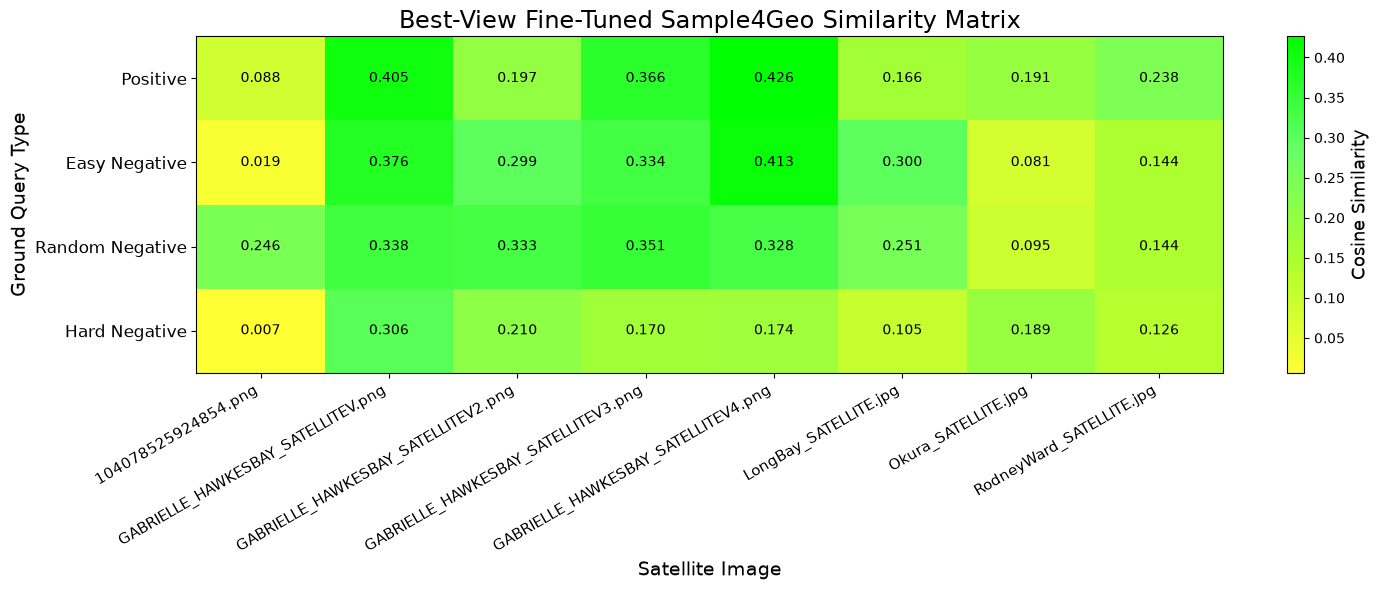

In [97]:
# ============================================================
# BEST-VIEW FINE-TUNED MODEL:
# EXTERNAL TEST SIMILARITY MATRIX
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.colors import LinearSegmentedColormap

import torch
import torch.nn.functional as F

from sample4geo.model import TimmModel
from sample4geo.transforms import get_transforms_val


# ============================================================
# 1. DEVICE + MODEL CONFIGURATION
# ============================================================

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model_name = (
    "convnext_base.fb_in22k_ft_in1k_384"
)

print("Device:", device)


# ============================================================
# 2. PATH TO BEST-VIEW FINE-TUNED CHECKPOINT
# ============================================================

BESTVIEW_MODEL_PATH = Path(
    r"E:\python_project\Geo\Sample4Geo"
    r"\FT\CVIAN_bestview_run01"
    r"\best_model.pth"
)

print(
    "Loading best-view checkpoint:"
)

print(
    BESTVIEW_MODEL_PATH
)


# ============================================================
# 3. CREATE MODEL ARCHITECTURE
# ============================================================

bestview_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)


# ============================================================
# 4. LOAD BEST-VIEW FINE-TUNED WEIGHTS
# ============================================================

bestview_state = torch.load(
    BESTVIEW_MODEL_PATH,
    map_location="cpu"
)

load_result = (
    bestview_model.load_state_dict(
        bestview_state,
        strict=True
    )
)

print(
    "\nCheckpoint loading:",
    load_result
)


# Move to GPU
bestview_model = (
    bestview_model.to(device)
)

# Inference mode
bestview_model.eval()


# ============================================================
# 5. RECREATE VALIDATION / TEST PREPROCESSING
#
# IMPORTANT:
# Use deterministic validation transforms.
# Do NOT use training augmentation for evaluation.
# ============================================================

data_config = (
    bestview_model.get_config()
)

mean = data_config["mean"]
std = data_config["std"]


# Same dimensions used during CVIAN fine-tuning
image_size_ground = (
    384,
    384
)

image_size_satellite = (
    384,
    384
)


sat_transform_bestview, ground_transform_bestview = (
    get_transforms_val(
        image_size_satellite,
        image_size_ground,
        mean=mean,
        std=std
    )
)


# ============================================================
# 6. EMBEDDING FUNCTION
# ============================================================

def get_bestview_embedding(
    image_path,
    transform
):

    # Read image
    img = np.array(
        Image.open(
            image_path
        ).convert("RGB")
    )


    # Apply Sample4Geo preprocessing
    tensor = transform(
        image=img
    )["image"]


    # Add batch dimension
    tensor = (
        tensor
        .unsqueeze(0)
        .to(device)
    )


    # Generate embedding
    with torch.inference_mode():

        embedding = (
            bestview_model(
                tensor
            )
        )


        # L2 normalization so dot product
        # becomes cosine similarity
        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )


    return embedding


# ============================================================
# 7. DEFINE THE FOUR EXTERNAL GROUND QUERIES
# ============================================================

ground_folder = Path(
    r"E:\python_project\Geo\Test_ground_image"
)


query_groups = {

    "Positive":
        ground_folder
        / "GABRIELLE_HAWKESBAY_CROSSV.png",

    "Easy Negative":
        ground_folder
        / "Easy_negative.png",

    "Random Negative":
        ground_folder
        / "random_negative.png",

    "Hard Negative":
        ground_folder
        / "Hard_negative.jpg"
}


# ============================================================
# 8. FIND ALL EXTERNAL SATELLITE TEST IMAGES
# ============================================================

satellite_folder = Path(
    r"E:\python_project\Geo\Test_sat_image"
)


satellite_files = []

for extension in [
    "*.png",
    "*.jpg",
    "*.jpeg"
]:

    satellite_files.extend(
        satellite_folder.glob(
            extension
        )
    )


satellite_files = sorted(
    satellite_files
)


print(
    "\nNumber of satellite images:",
    len(satellite_files)
)

for path in satellite_files:

    print(
        path.name
    )


# ============================================================
# 9. PRECOMPUTE SATELLITE EMBEDDINGS
#
# We only need to encode each satellite once.
# ============================================================

satellite_embeddings_bestview = {}


for sat_path in satellite_files:

    satellite_embedding = (
        get_bestview_embedding(
            sat_path,
            sat_transform_bestview
        )
    )


    satellite_embeddings_bestview[
        sat_path.name
    ] = satellite_embedding


print(
    "\nSatellite embeddings completed:",
    len(
        satellite_embeddings_bestview
    )
)


# ============================================================
# 10. COMPARE EACH GROUND QUERY AGAINST EVERY SATELLITE
# ============================================================

results_bestview = []


for (
    query_type,
    ground_path
) in query_groups.items():


    # Generate ground embedding
    ground_embedding = (
        get_bestview_embedding(
            ground_path,
            ground_transform_bestview
        )
    )


    # Compare against every satellite
    for (
        sat_name,
        sat_embedding
    ) in satellite_embeddings_bestview.items():


        cosine_similarity = (
            ground_embedding
            @ sat_embedding.T
        ).item()


        results_bestview.append({

            "query_type":
                query_type,

            "ground_image":
                ground_path.name,

            "satellite_image":
                sat_name,

            "cosine_similarity":
                cosine_similarity
        })


# ============================================================
# 11. CREATE RESULTS DATAFRAME
# ============================================================

df_bestview = pd.DataFrame(
    results_bestview
)


print(
    "\nBest-view fine-tuned similarity results:"
)

display(
    df_bestview
)


# ============================================================
# 12. CREATE SIMILARITY MATRIX
# ============================================================

heatmap_bestview = (
    df_bestview.pivot(
        index="query_type",
        columns="satellite_image",
        values="cosine_similarity"
    )
)


# Keep meaningful row order
row_order = [

    "Positive",

    "Easy Negative",

    "Random Negative",

    "Hard Negative"
]


heatmap_bestview = (
    heatmap_bestview.reindex(
        row_order
    )
)


# Preserve satellite filename order
heatmap_bestview = (
    heatmap_bestview.reindex(
        columns=[
            path.name
            for path
            in satellite_files
        ]
    )
)


# ============================================================
# 13. CUSTOM YELLOW → GREEN COLOUR MAP
# ============================================================

custom_cmap = (
    LinearSegmentedColormap.from_list(
        "yellow_green_bestview",

        [
            "#FFFF33",   # low
            "#ADFF2F",
            "#66FF66",
            "#00FF00"    # high
        ]
    )
)


# ============================================================
# 14. DRAW SIMILARITY MATRIX
# ============================================================

plt.figure(
    figsize=(15, 6)
)


im = plt.imshow(
    heatmap_bestview.values,
    aspect="auto",
    cmap=custom_cmap
)


# X-axis
plt.xticks(
    ticks=range(
        len(
            heatmap_bestview.columns
        )
    ),

    labels=(
        heatmap_bestview.columns
    ),

    rotation=30,
    ha="right",
    fontsize=11
)


# Y-axis
plt.yticks(
    ticks=range(
        len(
            heatmap_bestview.index
        )
    ),

    labels=(
        heatmap_bestview.index
    ),

    fontsize=12
)


# Title
plt.title(
    "Best-View Fine-Tuned Sample4Geo Similarity Matrix",
    fontsize=17
)


plt.xlabel(
    "Satellite Image",
    fontsize=14
)


plt.ylabel(
    "Ground Query Type",
    fontsize=14
)


# ============================================================
# 15. ADD COSINE VALUES INSIDE EACH CELL
# ============================================================

for i in range(
    heatmap_bestview.shape[0]
):

    for j in range(
        heatmap_bestview.shape[1]
    ):

        value = (
            heatmap_bestview.values[
                i,
                j
            ]
        )


        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )


# ============================================================
# 16. COLOR BAR
# ============================================================

cbar = plt.colorbar(
    im
)

cbar.set_label(
    "Cosine Similarity",
    fontsize=13
)


plt.tight_layout()

plt.show()